Maximum Values:
Company    Microsoft Gaming
Open           42501.562147
Name: 836, dtype: object
Company    Microsoft Gaming
Close          42339.574656
Name: 835, dtype: object
Company    Microsoft Gaming
High           44366.796078
Name: 836, dtype: object
Company    Microsoft Gaming
Low            39048.652491
Name: 836, dtype: object


Minimum Values:
Company    Sony Interactive Entertainment
Open                               1.1664
Name: 155, dtype: object
Company    Sony Interactive Entertainment
Close                              1.1688
Name: 154, dtype: object
Company    Sony Interactive Entertainment
High                                1.356
Name: 155, dtype: object
Company    Sony Interactive Entertainment
Low                                1.1484
Name: 155, dtype: object


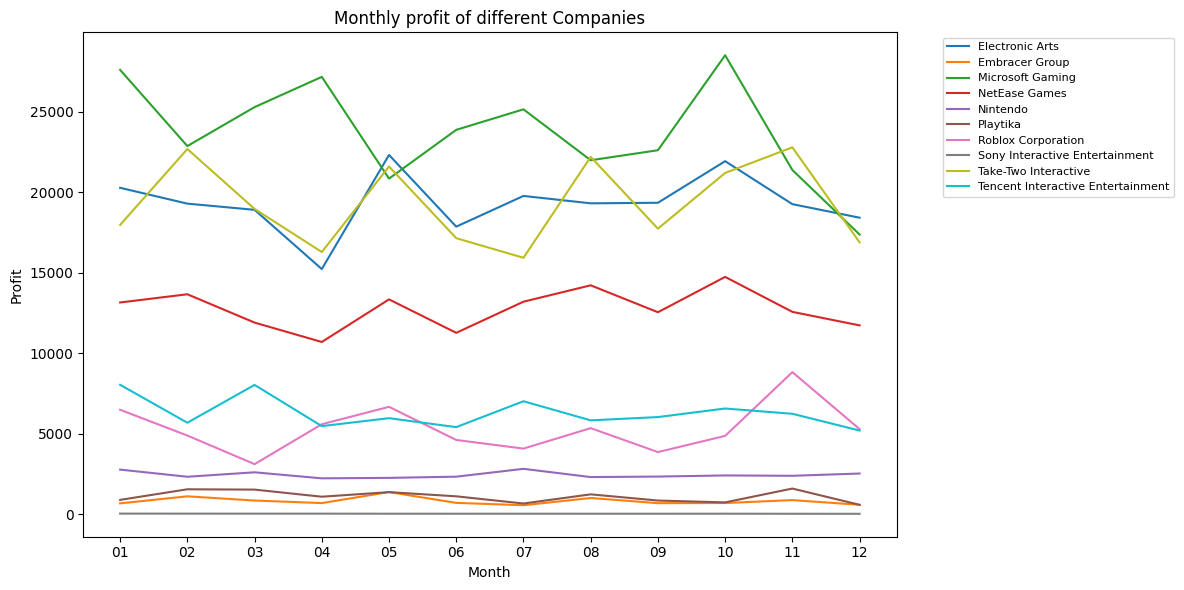

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
df = pd.read_csv("Top10VideoGameStocks.csv")
usd= 94.73
jpy= 0.6
hkd= 12.1
sek = 9.55
df.loc[df['Currency']== 'USD', ['Open', 'High', 'Low', 'Close']]*= usd
df.loc[df['Currency']== 'JPY', ['Open', 'High', 'Low', 'Close']]*= jpy
df.loc[df['Currency']== 'HKD', ['Open', 'High', 'Low', 'Close']]*= hkd
df.loc[df['Currency']== 'SEK', ['Open', 'High', 'Low', 'Close']]*= sek
df = df.drop(columns= ['Adj Close', 'Currency'])
df.to_csv('updated_data.csv',index=False)
print("Maximum Values:")
print(df.loc[df['Open'].idxmax(), ['Company', 'Open']])
print(df.loc[df['Close'].idxmax(), ['Company', 'Close']])
print(df.loc[df['High'].idxmax(), ['Company', 'High']])
print(df.loc[df['Low'].idxmax(), ['Company', 'Low']])
print("\n")
print("Minimum Values:")
print(df.loc[df['Open'].idxmin(), ['Company', 'Open']])
print(df.loc[df['Close'].idxmin(), ['Company','Close'] ])
print(df.loc[df['High'].idxmin(), ['Company', 'High']])
print(df.loc[df['Low'].idxmin(), ['Company','Low']])
df['Profit']= df['High']-df['Low']
df['Month']= df['Date'].str[5:7]

monthly_profit = df.groupby(['Company', 'Month'])['Profit'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(data= monthly_profit, x='Month', y='Profit', hue= 'Company')
plt.xlabel('Month')
plt.ylabel('Profit')
plt.title('Monthly profit of different Companies')
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('profit_per_month.png', dpi=300, bbox_inches= 'tight')
plt.show()







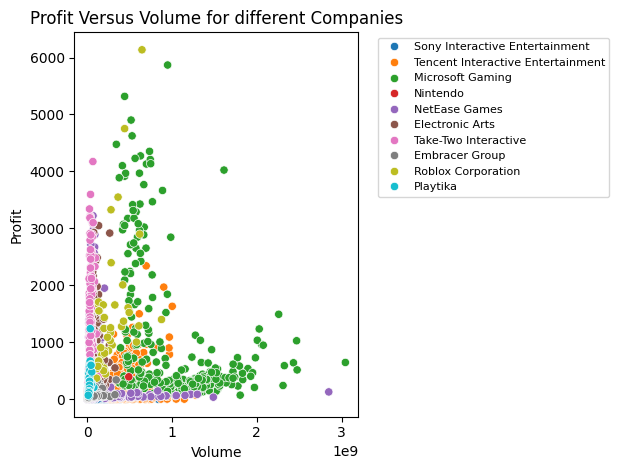

In [40]:
sns.scatterplot(data= df, x= 'Volume', y= 'Profit', hue= 'Company')
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', fontsize=8)
plt.title("Profit Versus Volume for different Companies")
plt.tight_layout()
plt.savefig('profit_per_volume.png', dpi=300, bbox_inches='tight')
plt.show()


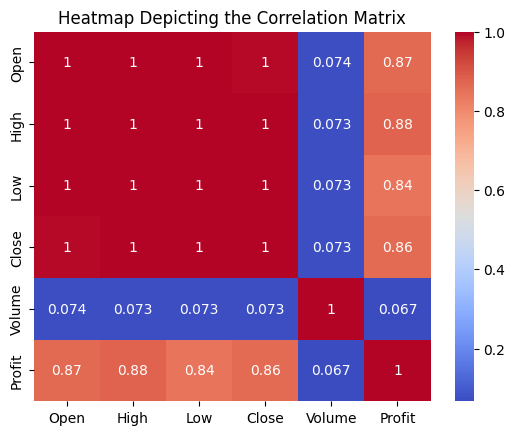

In [41]:
sns.heatmap(df.corr(numeric_only= True), annot= True, cmap = 'coolwarm')
plt.title("Heatmap Depicting the Correlation Matrix")
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

